In [1]:
import pandas as pd
import numpy as np
from librosa.util import find_files
import librosa
import os
import pickle
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader
import torch.nn.functional as F
from dataset import ASVspoof2019
from evaluate_tDCF_asvspoof19 import compute_eer_and_tdcf
from collections import defaultdict
from utils import visualize, get_features, compare_exps, visualize_dev_and_eval, test_checkpoint_model

In [2]:
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

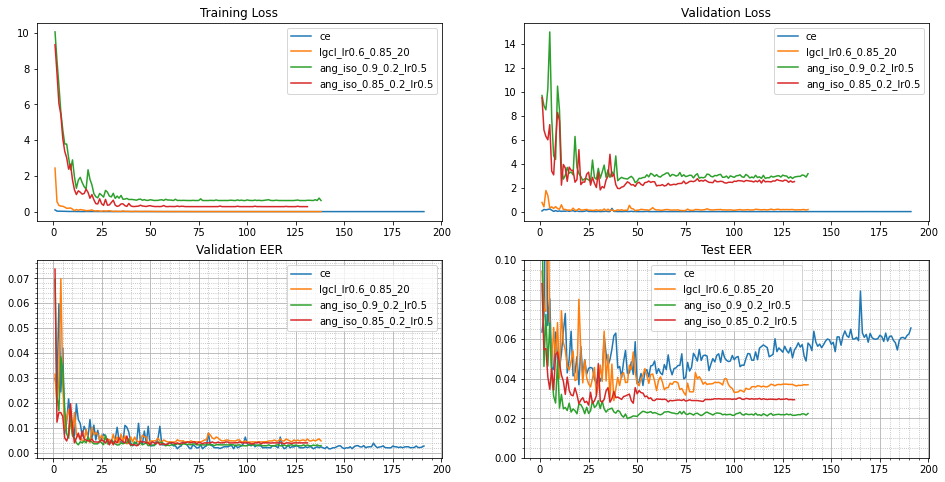

In [2]:
exp_dirs = ["ce", "lgcl_lr0.6_0.85_20", "ang_iso_0.9_0.2_lr0.5", "ang_iso_0.85_0.2_lr0.5"]
compare_exps(exp_dirs, "/data/neil/antiRes/models1015")

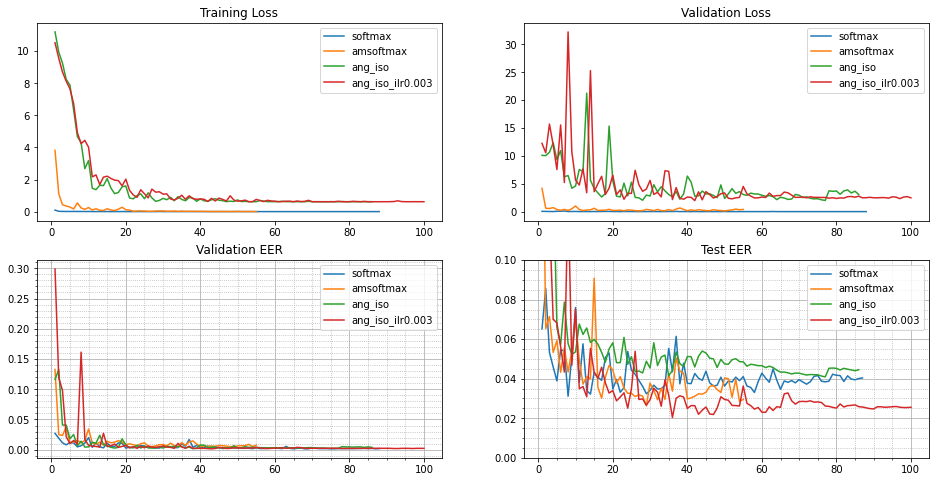

In [3]:
exp_dirs = ["softmax", "amsoftmax", "ang_iso", "ang_iso_ilr0.003"]
compare_exps(exp_dirs, "/data/neil/antiRes/models1019")

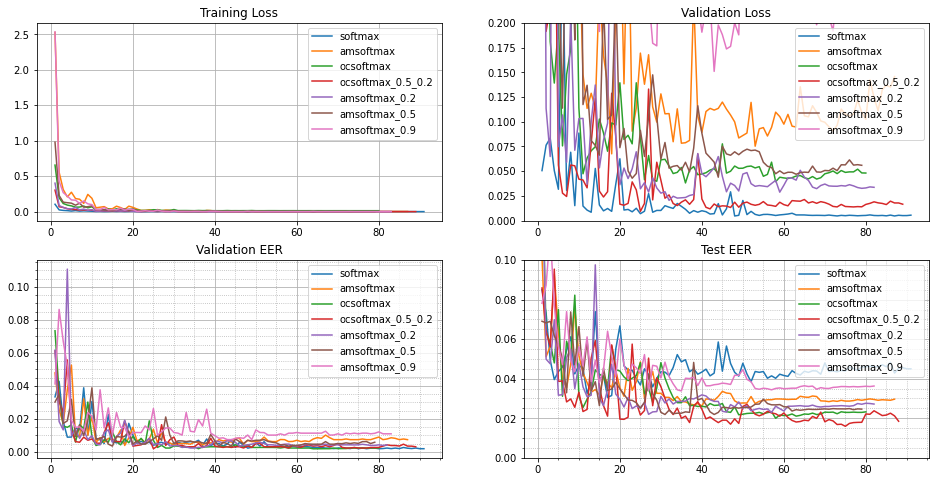

In [5]:
exp_dirs = ["softmax", "amsoftmax", "ocsoftmax","ocsoftmax_0.5_0.2", "amsoftmax_0.2", "amsoftmax_0.5", "amsoftmax_0.9"]
compare_exps(exp_dirs, "/data/neil/antiRes/models1020")

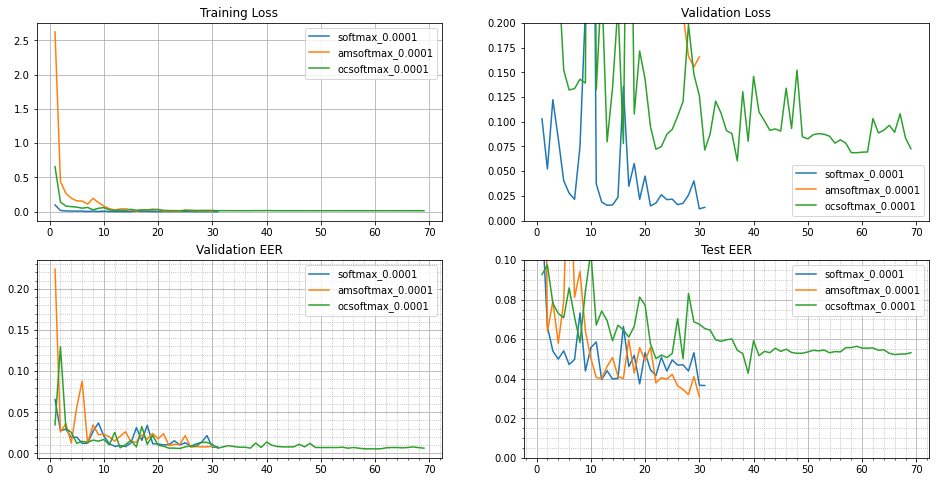

In [3]:
exp_dirs = ["softmax_0.0001", "amsoftmax_0.0001",  "ocsoftmax_0.0001"]
compare_exps(exp_dirs, "/data/neil/antiRes/models1020")

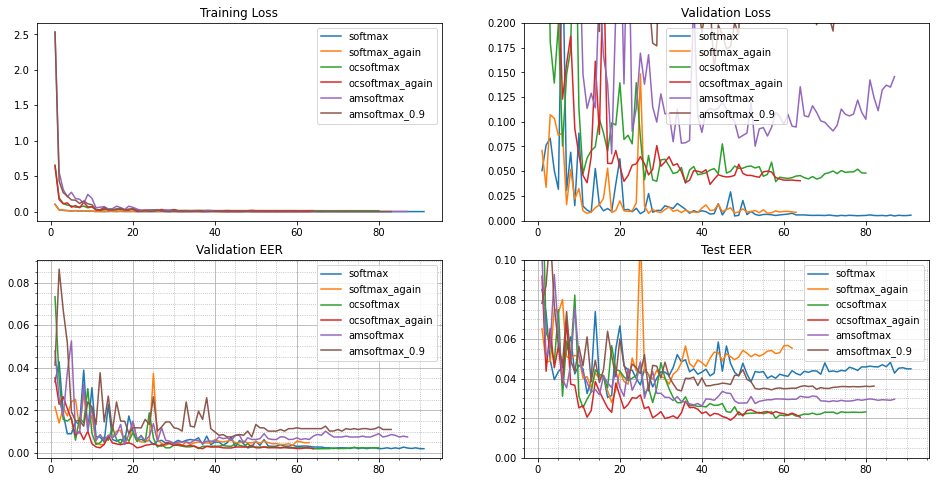

In [10]:
exp_dirs = ["softmax", "softmax_again", "ocsoftmax","ocsoftmax_again", "amsoftmax", "amsoftmax_0.9"]
compare_exps(exp_dirs, "/data/neil/antiRes/models1020")

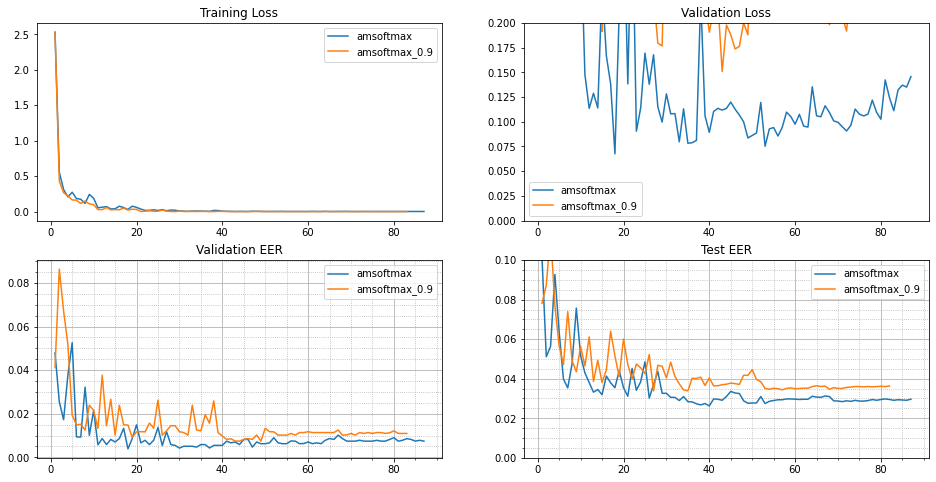

In [18]:
exp_dirs = ["amsoftmax", "amsoftmax_0.9"]
compare_exps(exp_dirs, "/data/neil/antiRes/models1020")

100%|██████████| 777/777 [01:01<00:00, 12.57it/s]


t-DCF evaluation from [Nbona=2548, Nspoof=22296] trials

   tDCF_norm(s) =  2.40595 x Pmiss_cm(s) + Pfa_cm(s)


CM SYSTEM
   EER            =  0.47095 % (Equal error rate for countermeasure)

TANDEM
   min-tDCF       =  0.01492


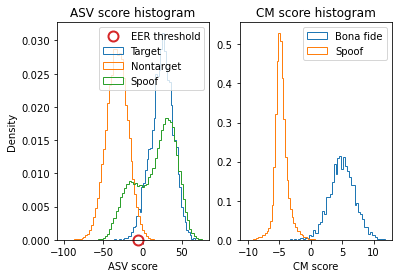

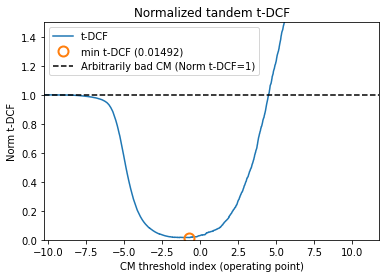

100%|██████████| 2227/2227 [03:03<00:00, 12.12it/s]


t-DCF evaluation from [Nbona=7355, Nspoof=63882] trials

   tDCF_norm(s) =  2.40595 x Pmiss_cm(s) + Pfa_cm(s)


CM SYSTEM
   EER            =  4.96088 % (Equal error rate for countermeasure)

TANDEM
   min-tDCF       =  0.13405


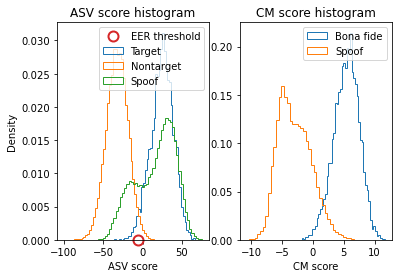

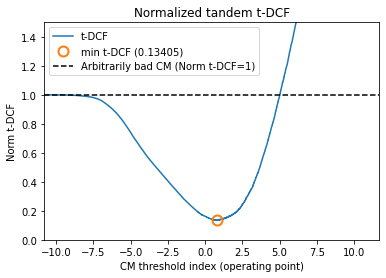

(0.04960876944875271, 0.13404849454293613)

In [9]:
feat_model_path = "/data/neil/antiRes/models1020/softmax_again/checkpoint/anti-spoofing_cqcc_model_%d.pt" % 48
loss_model_path = "None"
test_checkpoint_model(feat_model_path, loss_model_path, "dev", None, vis=False)
test_checkpoint_model(feat_model_path, loss_model_path, "eval", None, vis=False)

100%|██████████| 777/777 [01:02<00:00, 12.46it/s]


t-DCF evaluation from [Nbona=2548, Nspoof=22296] trials

   tDCF_norm(s) =  2.40595 x Pmiss_cm(s) + Pfa_cm(s)


CM SYSTEM
   EER            =  0.22762 % (Equal error rate for countermeasure)

TANDEM
   min-tDCF       =  0.00584


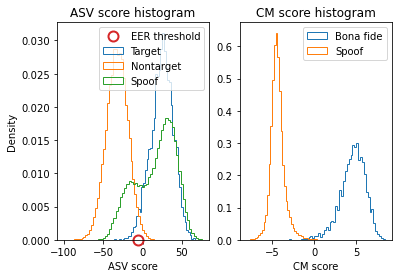

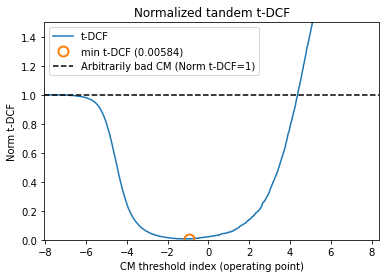

100%|██████████| 2227/2227 [02:59<00:00, 12.42it/s]


t-DCF evaluation from [Nbona=7355, Nspoof=63882] trials

   tDCF_norm(s) =  2.40595 x Pmiss_cm(s) + Pfa_cm(s)


CM SYSTEM
   EER            =  4.42049 % (Equal error rate for countermeasure)

TANDEM
   min-tDCF       =  0.11531


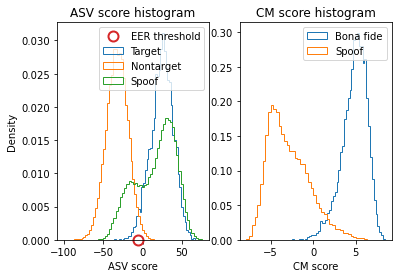

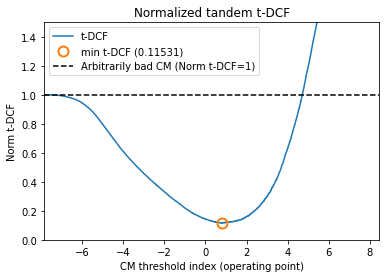

(0.044204893535542494, 0.11530954313524316)

In [11]:
feat_model_path = "/data/neil/antiRes/models1020/softmax/checkpoint/anti-spoofing_cqcc_model_%d.pt" % 78
loss_model_path = "None"
test_checkpoint_model(feat_model_path, loss_model_path, "dev", None, vis=False)
test_checkpoint_model(feat_model_path, loss_model_path, "eval", None, vis=False)

100%|██████████| 777/777 [01:03<00:00, 12.21it/s]


t-DCF evaluation from [Nbona=2548, Nspoof=22296] trials

   tDCF_norm(s) =  2.40595 x Pmiss_cm(s) + Pfa_cm(s)


CM SYSTEM
   EER            =  0.42666 % (Equal error rate for countermeasure)

TANDEM
   min-tDCF       =  0.01294


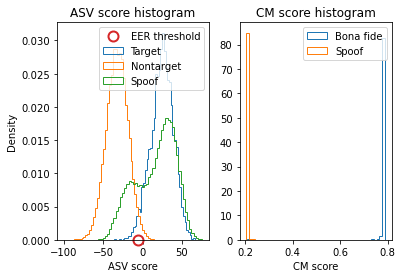

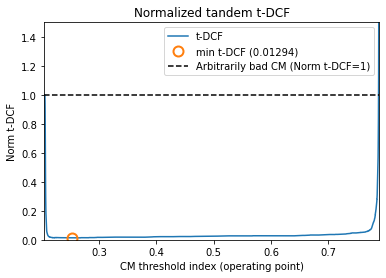

100%|██████████| 2227/2227 [03:06<00:00, 11.94it/s]


t-DCF evaluation from [Nbona=7355, Nspoof=63882] trials

   tDCF_norm(s) =  2.40595 x Pmiss_cm(s) + Pfa_cm(s)


CM SYSTEM
   EER            =  3.26111 % (Equal error rate for countermeasure)

TANDEM
   min-tDCF       =  0.08184


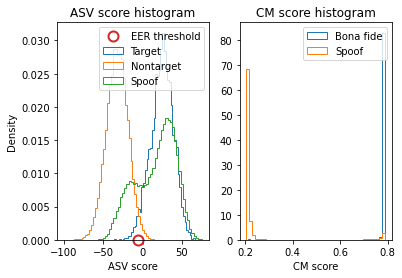

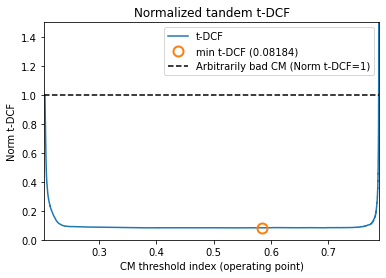

(0.032611101820953836, 0.08184143453329738)

In [19]:
feat_model_path = "/data/neil/antiRes/models1020/amsoftmax/checkpoint/anti-spoofing_cqcc_model_%d.pt" % 30
loss_model_path = "/data/neil/antiRes/models1020/amsoftmax/checkpoint/anti-spoofing_loss_model_%d.pt" % 30
test_checkpoint_model(feat_model_path, loss_model_path, "dev", "lgcl", vis=False)
test_checkpoint_model(feat_model_path, loss_model_path, "eval", "lgcl", vis=False)

100%|██████████| 777/777 [01:03<00:00, 12.18it/s]


t-DCF evaluation from [Nbona=2548, Nspoof=22296] trials

   tDCF_norm(s) =  2.40595 x Pmiss_cm(s) + Pfa_cm(s)


CM SYSTEM
   EER            =  1.33547 % (Equal error rate for countermeasure)

TANDEM
   min-tDCF       =  0.04386


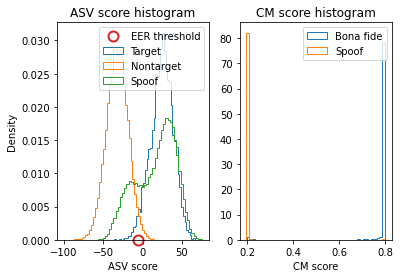

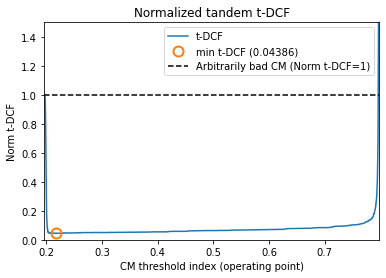

100%|██████████| 2227/2227 [03:04<00:00, 12.05it/s]


t-DCF evaluation from [Nbona=7355, Nspoof=63882] trials

   tDCF_norm(s) =  2.40595 x Pmiss_cm(s) + Pfa_cm(s)


CM SYSTEM
   EER            =  4.46045 % (Equal error rate for countermeasure)

TANDEM
   min-tDCF       =  0.13008


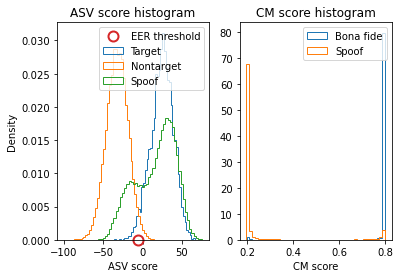

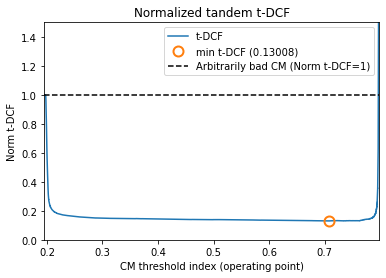

(0.044604509704127965, 0.13007966159944762)

In [20]:
feat_model_path = "/data/neil/antiRes/models1020/amsoftmax_0.9/checkpoint/anti-spoofing_cqcc_model_%d.pt" % 50
loss_model_path = "/data/neil/antiRes/models1020/amsoftmax_0.9/checkpoint/anti-spoofing_loss_model_%d.pt" % 50
test_checkpoint_model(feat_model_path, loss_model_path, "dev", "lgcl", vis=False)
test_checkpoint_model(feat_model_path, loss_model_path, "eval", "lgcl", vis=False)

100%|██████████| 777/777 [01:02<00:00, 12.34it/s]


t-DCF evaluation from [Nbona=2548, Nspoof=22296] trials

   tDCF_norm(s) =  2.40595 x Pmiss_cm(s) + Pfa_cm(s)


CM SYSTEM
   EER            =  0.19679 % (Equal error rate for countermeasure)

TANDEM
   min-tDCF       =  0.00557


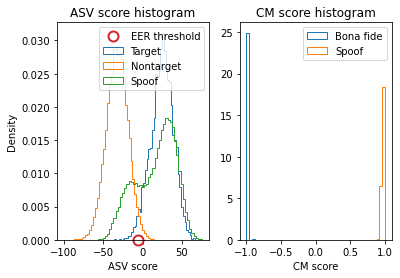

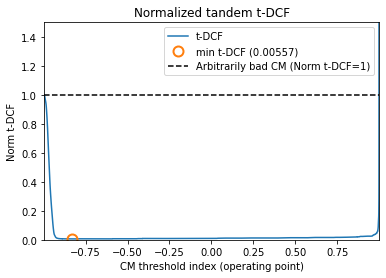

100%|██████████| 2227/2227 [03:05<00:00, 12.04it/s]


t-DCF evaluation from [Nbona=7355, Nspoof=63882] trials

   tDCF_norm(s) =  2.40595 x Pmiss_cm(s) + Pfa_cm(s)


CM SYSTEM
   EER            =  2.18870 % (Equal error rate for countermeasure)

TANDEM
   min-tDCF       =  0.05881


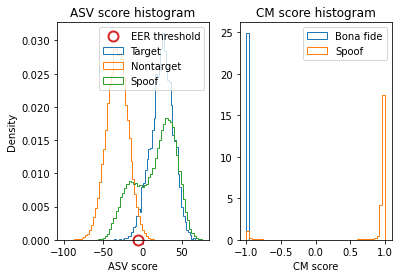

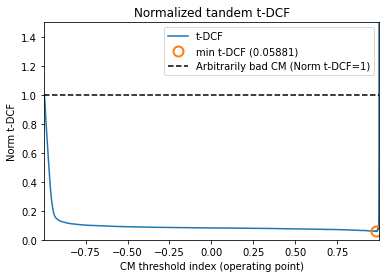

(0.021886984821670803, 0.058810888215956904)

In [15]:
feat_model_path = "/data/neil/antiRes/models1020/ocsoftmax/checkpoint/anti-spoofing_cqcc_model_%d.pt" % 68
loss_model_path = "/data/neil/antiRes/models1020/ocsoftmax/checkpoint/anti-spoofing_loss_model_%d.pt" % 68
test_checkpoint_model(feat_model_path, loss_model_path, "dev", "ang_iso", vis=False)
test_checkpoint_model(feat_model_path, loss_model_path, "eval", "ang_iso", vis=False)

100%|██████████| 777/777 [01:03<00:00, 12.25it/s]


t-DCF evaluation from [Nbona=2548, Nspoof=22296] trials

   tDCF_norm(s) =  2.40595 x Pmiss_cm(s) + Pfa_cm(s)


CM SYSTEM
   EER            =  0.19903 % (Equal error rate for countermeasure)

TANDEM
   min-tDCF       =  0.00674


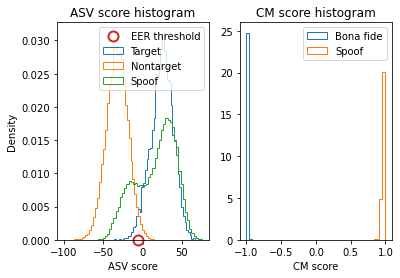

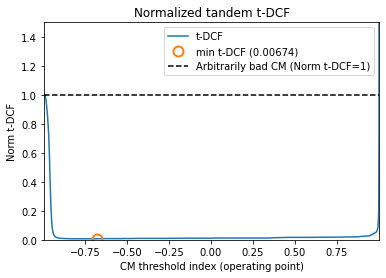

100%|██████████| 2227/2227 [03:02<00:00, 12.18it/s]


t-DCF evaluation from [Nbona=7355, Nspoof=63882] trials

   tDCF_norm(s) =  2.40595 x Pmiss_cm(s) + Pfa_cm(s)


CM SYSTEM
   EER            =  2.10721 % (Equal error rate for countermeasure)

TANDEM
   min-tDCF       =  0.05456


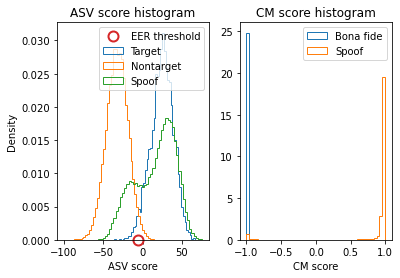

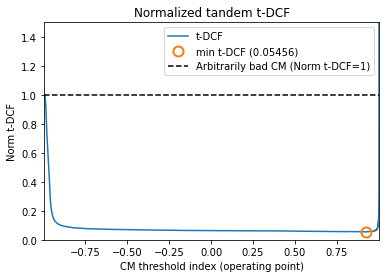

(0.02107209862269215, 0.05455675340246241)

In [16]:
feat_model_path = "/data/neil/antiRes/models1020/ocsoftmax_again/checkpoint/anti-spoofing_cqcc_model_%d.pt" % 66
loss_model_path = "/data/neil/antiRes/models1020/ocsoftmax_again/checkpoint/anti-spoofing_loss_model_%d.pt" % 66
test_checkpoint_model(feat_model_path, loss_model_path, "dev", "ang_iso", vis=False)
test_checkpoint_model(feat_model_path, loss_model_path, "eval", "ang_iso", vis=False)

/home/neil/anaconda3/envs/ocas/lib/python3.6/site-packages/torch/serialization.py:454: SourceChangeWarning: source code of class 'torch.nn.modules.conv.Conv2d' has changed. you can retrieve the original source code by accessing the object's source attribute or set `torch.nn.Module.dump_patches = True` and use the patch tool to revert the changes.
  warnings.warn(msg, SourceChangeWarning)
/home/neil/anaconda3/envs/ocas/lib/python3.6/site-packages/torch/serialization.py:454: SourceChangeWarning: source code of class 'torch.nn.modules.batchnorm.BatchNorm2d' has changed. you can retrieve the original source code by accessing the object's source attribute or set `torch.nn.Module.dump_patches = True` and use the patch tool to revert the changes.
  warnings.warn(msg, SourceChangeWarning)
/home/neil/anaconda3/envs/ocas/lib/python3.6/site-packages/torch/serialization.py:454: SourceChangeWarning: source code of class 'torch.nn.modules.activation.ReLU' has changed. you can retrieve the original s

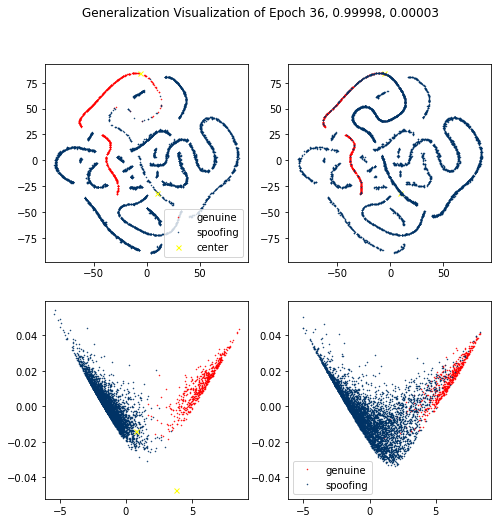

In [3]:
feat_model_path = "/data/neil/antiRes/models1015/ce/checkpoint/anti-spoofing_cqcc_model_%d.pt" % 36
# loss_model_path = "/data/neil/antiRes/models1015/ce/checkpoint/anti-spoofing_loss_model_%d.pt" % 36
center = torch.load(feat_model_path).fc_mu.weight.detach().cpu().numpy()
dev_feat, dev_labels, _ = get_features(feat_model_path, "dev")
eval_feat, eval_labels, _ = get_features(feat_model_path, "eval")
visualize_dev_and_eval(dev_feat, dev_labels, eval_feat, eval_labels, center, 36, "/data/neil/antiRes/models1015/ce")

In [ ]:
feat_model_path = "/data/neil/antiRes/models1019/softmax/checkpoint/anti-spoofing_cqcc_model_%d.pt" % 30
center = torch.load(feat_model_path).fc_mu.weight.detach().cpu().numpy()
dev_feat, dev_labels, _ = get_features(feat_model_path, "dev")
eval_feat, eval_labels, _ = get_features(feat_model_path, "eval")
visualize_dev_and_eval(dev_feat, dev_labels, eval_feat, eval_labels, center, 30, "/data/neil/antiRes/models1019/softmax")


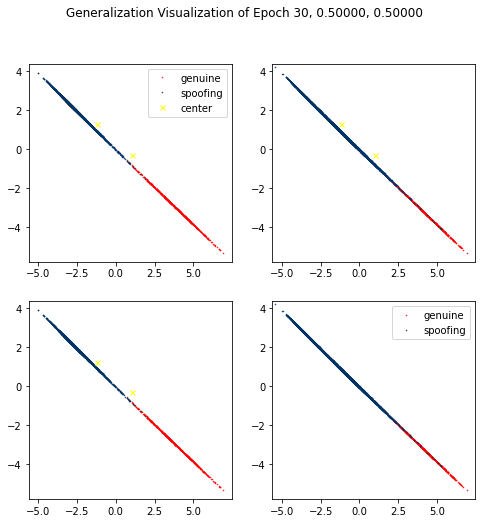

In [18]:
visualize_dev_and_eval(dev_feat, dev_labels, eval_feat, eval_labels, center, 30, "/data/neil/antiRes/models1019/softmax")


100%|██████████| 2227/2227 [03:25<00:00, 10.86it/s]


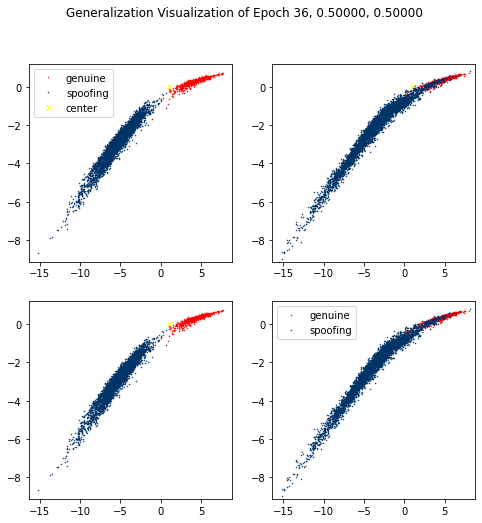

In [19]:
feat_model_path = "/data/neil/antiRes/models1019/ang_iso/checkpoint/anti-spoofing_cqcc_model_%d.pt" % 36
loss_model_path = "/data/neil/antiRes/models1019/ang_iso/checkpoint/anti-spoofing_loss_model_%d.pt" % 36
center = torch.load(loss_model_path).center.detach().cpu().numpy()
dev_feat, dev_labels, _ = get_features(feat_model_path, "dev")
eval_feat, eval_labels, _ = get_features(feat_model_path, "eval")
visualize_dev_and_eval(dev_feat, dev_labels, eval_feat, eval_labels, center, 36, "/data/neil/antiRes/models1019/ang_iso")


/home/neil/anaconda3/envs/ocas/lib/python3.6/site-packages/torch/serialization.py:454: SourceChangeWarning: source code of class 'loss.AngularIsoLoss' has changed. you can retrieve the original source code by accessing the object's source attribute or set `torch.nn.Module.dump_patches = True` and use the patch tool to revert the changes.
  warnings.warn(msg, SourceChangeWarning)
/home/neil/anaconda3/envs/ocas/lib/python3.6/site-packages/torch/serialization.py:454: SourceChangeWarning: source code of class 'torch.nn.modules.activation.Softplus' has changed. you can retrieve the original source code by accessing the object's source attribute or set `torch.nn.Module.dump_patches = True` and use the patch tool to revert the changes.
  warnings.warn(msg, SourceChangeWarning)
/home/neil/anaconda3/envs/ocas/lib/python3.6/site-packages/torch/serialization.py:454: SourceChangeWarning: source code of class 'torch.nn.modules.conv.Conv2d' has changed. you can retrieve the original source code by a

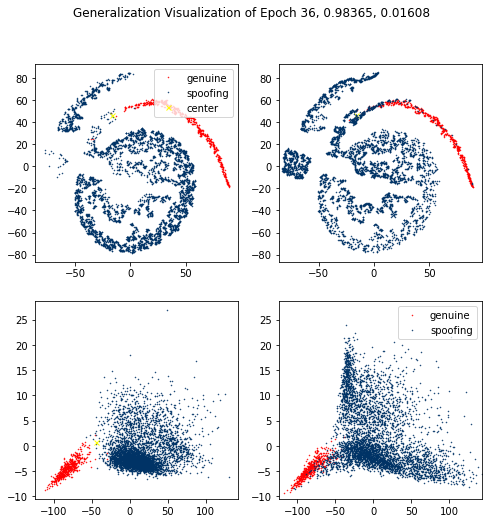

In [4]:
feat_model_path = "/data/neil/antiRes/models1015/ang_iso_0.9_0.2_lr0.5/checkpoint/anti-spoofing_cqcc_model_%d.pt" % 76
loss_model_path = "/data/neil/antiRes/models1015/ang_iso_0.9_0.2_lr0.5/checkpoint/anti-spoofing_loss_model_%d.pt" % 76
center = torch.load(loss_model_path).center.detach().cpu().numpy()
dev_feat, dev_labels, _ = get_features(feat_model_path, "dev")
eval_feat, eval_labels, _ = get_features(feat_model_path, "eval")
visualize_dev_and_eval(dev_feat, dev_labels, eval_feat, eval_labels, center, 76, "/data/neil/antiRes/models1015/ang_iso_0.9_0.2_lr0.5")



/home/neil/anaconda3/envs/ocas/lib/python3.6/site-packages/torch/serialization.py:454: SourceChangeWarning: source code of class 'loss.AngularIsoLoss' has changed. you can retrieve the original source code by accessing the object's source attribute or set `torch.nn.Module.dump_patches = True` and use the patch tool to revert the changes.
  warnings.warn(msg, SourceChangeWarning)
/home/neil/anaconda3/envs/ocas/lib/python3.6/site-packages/torch/serialization.py:454: SourceChangeWarning: source code of class 'torch.nn.modules.activation.Softplus' has changed. you can retrieve the original source code by accessing the object's source attribute or set `torch.nn.Module.dump_patches = True` and use the patch tool to revert the changes.
  warnings.warn(msg, SourceChangeWarning)
/home/neil/anaconda3/envs/ocas/lib/python3.6/site-packages/torch/serialization.py:454: SourceChangeWarning: source code of class 'torch.nn.modules.conv.Conv2d' has changed. you can retrieve the original source code by a

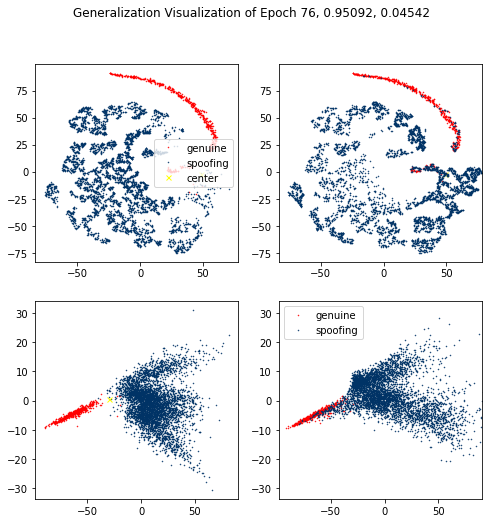

In [7]:
feat_model_path = "/data/neil/antiRes/models1015/ang_iso_0.85_0.2_lr0.5/checkpoint/anti-spoofing_cqcc_model_%d.pt" % 76
loss_model_path = "/data/neil/antiRes/models1015/ang_iso_0.85_0.2_lr0.5/checkpoint/anti-spoofing_loss_model_%d.pt" % 76
center = torch.load(loss_model_path).center.detach().cpu().numpy()
dev_feat, dev_labels, _ = get_features(feat_model_path, "dev")
eval_feat, eval_labels, _ = get_features(feat_model_path, "eval")
visualize_dev_and_eval(dev_feat, dev_labels, eval_feat, eval_labels, center, 76, "/data/neil/antiRes/models1015/ang_iso_0.85_0.2_lr0.5")


/home/neil/anaconda3/envs/ocas/lib/python3.6/site-packages/torch/serialization.py:454: SourceChangeWarning: source code of class 'loss.AngularIsoLoss' has changed. you can retrieve the original source code by accessing the object's source attribute or set `torch.nn.Module.dump_patches = True` and use the patch tool to revert the changes.
  warnings.warn(msg, SourceChangeWarning)
/home/neil/anaconda3/envs/ocas/lib/python3.6/site-packages/torch/serialization.py:454: SourceChangeWarning: source code of class 'torch.nn.modules.activation.Softplus' has changed. you can retrieve the original source code by accessing the object's source attribute or set `torch.nn.Module.dump_patches = True` and use the patch tool to revert the changes.
  warnings.warn(msg, SourceChangeWarning)
/home/neil/anaconda3/envs/ocas/lib/python3.6/site-packages/torch/serialization.py:454: SourceChangeWarning: source code of class 'torch.nn.modules.conv.Conv2d' has changed. you can retrieve the original source code by a

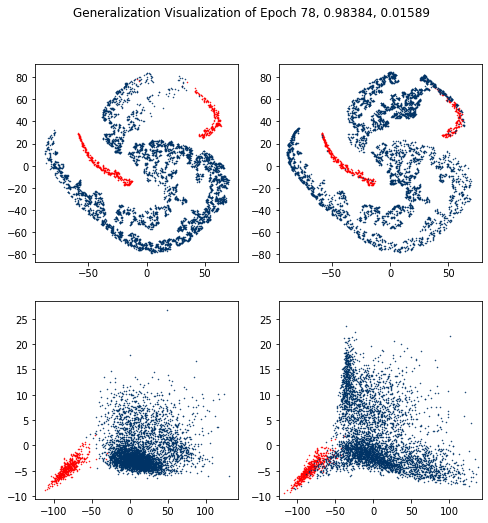

In [7]:
feat_model_path = "/data/neil/antiRes/models1015/ang_iso_0.9_0.2_lr0.5/checkpoint/anti-spoofing_cqcc_model_%d.pt" % 78
loss_model_path = "/data/neil/antiRes/models1015/ang_iso_0.9_0.2_lr0.5/checkpoint/anti-spoofing_loss_model_%d.pt" % 78
center = torch.load(loss_model_path).center.detach().cpu().numpy()
dev_feat, dev_labels, _ = get_features(feat_model_path, "dev")
eval_feat, eval_labels, _ = get_features(feat_model_path, "eval")
visualize_dev_and_eval(dev_feat, dev_labels, eval_feat, eval_labels, center, 78, "/data/neil/antiRes/models1015/ang_iso_0.9_0.2_lr0.5")


100%|██████████| 2227/2227 [03:15<00:00, 11.37it/s]


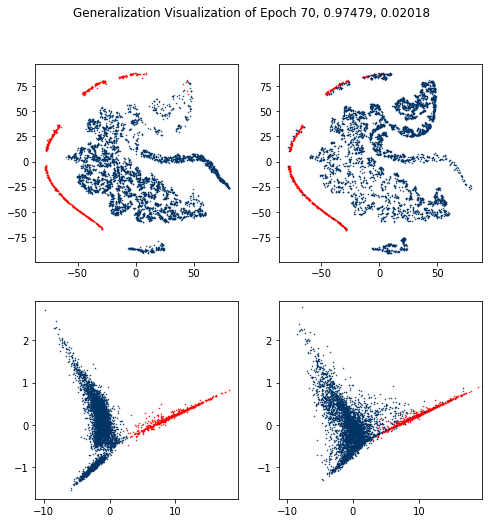

In [5]:
feat_model_path = "/data/neil/antiRes/models1020/ocsoftmax/checkpoint/anti-spoofing_cqcc_model_%d.pt" % 70
loss_model_path = "/data/neil/antiRes/models1020/ocsoftmax/checkpoint/anti-spoofing_loss_model_%d.pt" % 70
center = torch.load(loss_model_path).center.detach().cpu().numpy()
dev_feat, dev_labels, _ = get_features(feat_model_path, "dev")
eval_feat, eval_labels, _ = get_features(feat_model_path, "eval")
visualize_dev_and_eval(dev_feat, dev_labels, eval_feat, eval_labels, center, 70, "/data/neil/antiRes/models1020/ocsoftmax")


100%|██████████| 2227/2227 [03:16<00:00, 11.31it/s]


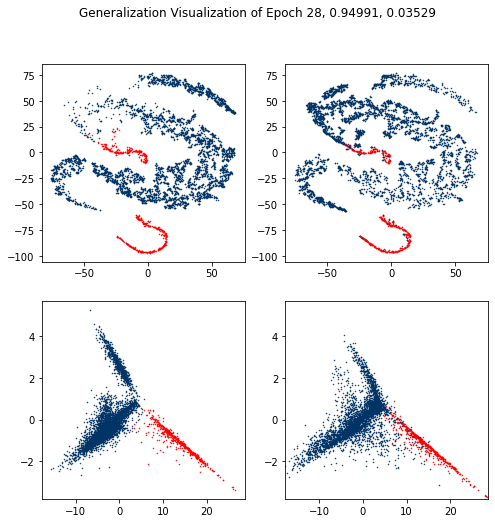

In [3]:
feat_model_path = "/data/neil/antiRes/models1020/ocsoftmax_again/checkpoint/anti-spoofing_cqcc_model_%d.pt" % 28
loss_model_path = "/data/neil/antiRes/models1020/ocsoftmax_again/checkpoint/anti-spoofing_loss_model_%d.pt" % 28
center = torch.load(loss_model_path).center.detach().cpu().numpy()
dev_feat, dev_labels, _ = get_features(feat_model_path, "dev")
eval_feat, eval_labels, _ = get_features(feat_model_path, "eval")
visualize_dev_and_eval(dev_feat, dev_labels, eval_feat, eval_labels, center, 28, "/data/neil/antiRes/models1020/ocsoftmax_again")


100%|██████████| 2227/2227 [03:22<00:00, 11.02it/s]


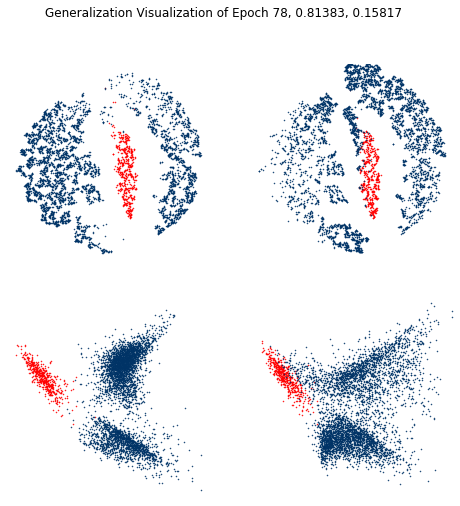

In [3]:
feat_model_path = "/data/neil/antiRes/models1020/ocsoftmax_0.5_0.2/checkpoint/anti-spoofing_cqcc_model_%d.pt" % 78
loss_model_path = "/data/neil/antiRes/models1020/ocsoftmax_0.5_0.2/checkpoint/anti-spoofing_loss_model_%d.pt" % 78
center = torch.load(loss_model_path).center.detach().cpu().numpy()
dev_feat, dev_labels, _ = get_features(feat_model_path, "dev")
eval_feat, eval_labels, _ = get_features(feat_model_path, "eval")
visualize_dev_and_eval(dev_feat, dev_labels, eval_feat, eval_labels, center, 78, "/data/neil/antiRes/models1020/ocsoftmax_0.5_0.2")


100%|██████████| 2227/2227 [03:01<00:00, 12.29it/s]


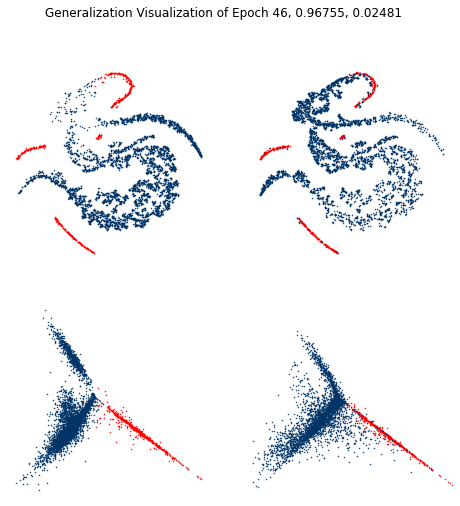

In [7]:
feat_model_path = "/data/neil/antiRes/models1020/ocsoftmax_again/checkpoint/anti-spoofing_cqcc_model_%d.pt" % 46
loss_model_path = "/data/neil/antiRes/models1020/ocsoftmax_again/checkpoint/anti-spoofing_loss_model_%d.pt" % 46
center = torch.load(loss_model_path).center.detach().cpu().numpy()
dev_feat, dev_labels, _ = get_features(feat_model_path, "dev")
eval_feat, eval_labels, _ = get_features(feat_model_path, "eval")
visualize_dev_and_eval(dev_feat, dev_labels, eval_feat, eval_labels, center, 46, "/data/neil/antiRes/models1020/ocsoftmax_again")


/home/neil/anaconda3/envs/ocas/lib/python3.6/site-packages/torch/serialization.py:454: SourceChangeWarning: source code of class 'torch.nn.modules.conv.Conv2d' has changed. you can retrieve the original source code by accessing the object's source attribute or set `torch.nn.Module.dump_patches = True` and use the patch tool to revert the changes.
  warnings.warn(msg, SourceChangeWarning)
/home/neil/anaconda3/envs/ocas/lib/python3.6/site-packages/torch/serialization.py:454: SourceChangeWarning: source code of class 'torch.nn.modules.batchnorm.BatchNorm2d' has changed. you can retrieve the original source code by accessing the object's source attribute or set `torch.nn.Module.dump_patches = True` and use the patch tool to revert the changes.
  warnings.warn(msg, SourceChangeWarning)
/home/neil/anaconda3/envs/ocas/lib/python3.6/site-packages/torch/serialization.py:454: SourceChangeWarning: source code of class 'torch.nn.modules.activation.ReLU' has changed. you can retrieve the original s

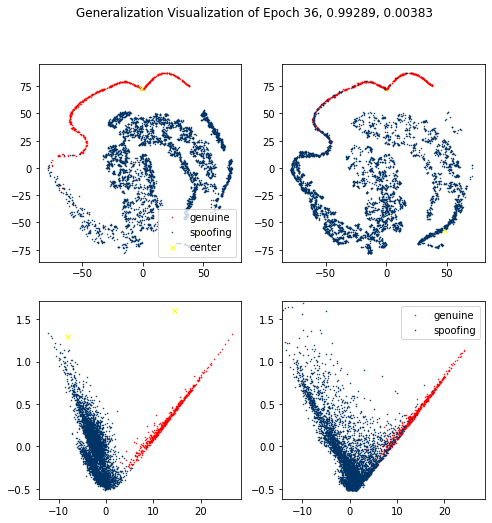

In [6]:
feat_model_path = "/data/neil/antiRes/models1015/lgcl_lr0.6_0.85_20/checkpoint/anti-spoofing_cqcc_model_%d.pt" % 76
loss_model_path = "/data/neil/antiRes/models1015/lgcl_lr0.6_0.85_20/checkpoint/anti-spoofing_loss_model_%d.pt" % 76
center = torch.load(loss_model_path).centers.detach().cpu().numpy()
dev_feat, dev_labels, _ = get_features(feat_model_path, "dev")
eval_feat, eval_labels, _ = get_features(feat_model_path, "eval")
visualize_dev_and_eval(dev_feat, dev_labels, eval_feat, eval_labels, center, 36, "/data/neil/antiRes/models1015/lgcl_lr0.6_0.85_20")


/home/neil/anaconda3/envs/ocas/lib/python3.6/site-packages/torch/serialization.py:454: SourceChangeWarning: source code of class 'torch.nn.modules.conv.Conv2d' has changed. you can retrieve the original source code by accessing the object's source attribute or set `torch.nn.Module.dump_patches = True` and use the patch tool to revert the changes.
  warnings.warn(msg, SourceChangeWarning)
/home/neil/anaconda3/envs/ocas/lib/python3.6/site-packages/torch/serialization.py:454: SourceChangeWarning: source code of class 'torch.nn.modules.batchnorm.BatchNorm2d' has changed. you can retrieve the original source code by accessing the object's source attribute or set `torch.nn.Module.dump_patches = True` and use the patch tool to revert the changes.
  warnings.warn(msg, SourceChangeWarning)
/home/neil/anaconda3/envs/ocas/lib/python3.6/site-packages/torch/serialization.py:454: SourceChangeWarning: source code of class 'torch.nn.modules.activation.ReLU' has changed. you can retrieve the original s

t-DCF evaluation from [Nbona=7355, Nspoof=63882] trials

   tDCF_norm(s) =  2.40595 x Pmiss_cm(s) + Pfa_cm(s)


CM SYSTEM
   EER            =  2.20019 % (Equal error rate for countermeasure)

TANDEM
   min-tDCF       =  0.05488


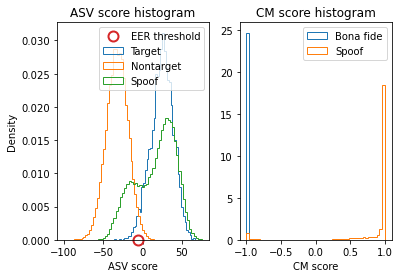

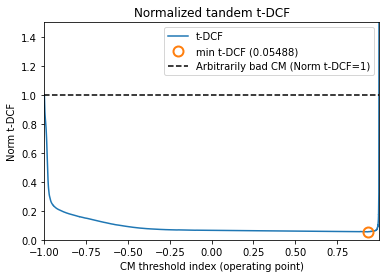

(0.022001927372423635, 0.05487790124695398)

In [12]:
feat_model_path = "/data/neil/antiRes/models1015/ang_iso_0.9_0.2_lr0.5/checkpoint/anti-spoofing_cqcc_model_%d.pt" % 76
loss_model_path = "/data/neil/antiRes/models1015/ang_iso_0.9_0.2_lr0.5/checkpoint/anti-spoofing_loss_model_%d.pt" % 76
test_checkpoint_model(feat_model_path, loss_model_path, "eval", "ang_iso", vis=False)

In [ ]:
import pandas as pd
import numpy as np
from librosa.util import find_files
import librosa
import os
import pickle
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader
import torch.nn.functional as F
from dataset import ASVspoof2019
from evaluate_tDCF_asvspoof19 import compute_eer_and_tdcf
from collections import defaultdict
from utils import visualize, get_features, compare_exps, visualize_dev_and_eval